<a href="https://colab.research.google.com/github/europecodingschool/ECS---VB---YZ---08.26/blob/main/VB_YZ_Ders_25_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics

In [3]:
import cv2
import matplotlib.pyplot as plt
import urllib.request
import ultralytics
from ultralytics import YOLO

In [7]:
# 1 adet otobüs resmi ve 1 adet video kaydı çektik. Hazır kütüphanelerden. Kendimizde içeri başka bir görsel ve video da alsak olurdu.
otobus_adresi = ("https://raw.githubusercontent.com/ultralytics/ultralytics/"
"main/ultralytics/assets/bus.jpg")
urllib.request.urlretrieve(otobus_adresi, "otobus.jpg")

video_adresi = ("https://raw.githubusercontent.com/opencv/opencv/"
 "4.x/samples/data/vtest.avi")

urllib.request.urlretrieve(video_adresi, "yayalar.avi")

print("YOLO Sürüm", ultralytics.__version__)


YOLO Sürüm 8.4.211


(1080, 810, 3)


<function matplotlib.pyplot.show(close=None, block=None)>

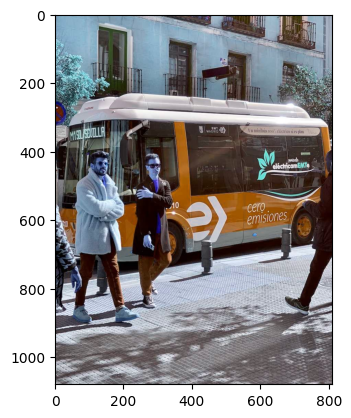

In [11]:
#FOTOĞRAFA BAKALIM

otobus = cv2.imread("otobus.jpg")
print(otobüs.shape)
plt.imshow(otobus)
plt.show

In [16]:
# MODELİ YÜKLEME

model = YOLO("yolo26n-seg.pt")

print("Modelin tadığı sınıf sayısı:", len(model.names))
print("0 numaralı sınıf", model.names[0])
print("2 numaralı sınıf", model.names[2])
print("15 numaralı sınıf", model.names[15])


Modelin tadığı sınıf sayısı: 80
0 numaralı sınıf person
2 numaralı sınıf car
15 numaralı sınıf cat


In [22]:
#NESNELERİ TESPİT ETMEK
#Fotoğrafı opencv ile okuyoruz. YOLO, olduğu gibi BGR formatını kabul eder. RGB ye çevirmeye gerek yok.

otobus = cv2.imread("otobus.jpg") # Fotoprafı opencv ile oku.

sonuclar = model(otobus,conf=0.25, verbose=False) # conf: güven eşiği baz değer 0.25
sonuc = sonuclar[0]
print("Bulunan Nesne Sayısı:", len(sonuc.boxes))
for kutu in sonuc.boxes:
  sinif_no = int(kutu.cls[0])
  guven = float(kutu.conf[0])
  print("Sınıf:", model.names[sinif_no], "Güven:", guven)


Bulunan Nesne Sayısı: 5
Sınıf: person Güven: 0.8770042657852173
Sınıf: person Güven: 0.8631635904312134
Sınıf: bus Güven: 0.8555253148078918
Sınıf: person Güven: 0.8106316328048706
Sınıf: person Güven: 0.6484107375144958


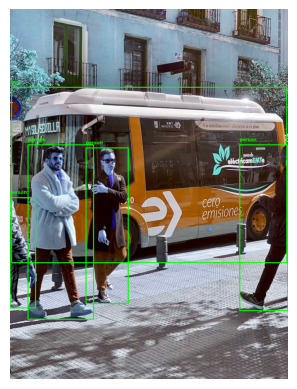

In [24]:
#KUTULARI ÇİZELİM VE SAYALIM.

def kutulari_ciz(goruntu, sonuc):
  for kutu in sonuc.boxes:
    sinif_no = int(kutu.cls[0])
    guven = float(kutu.conf[0])
    x1, y1, x2, y2 = kutu.xyxy[0].tolist()
    x1, y1, x2, y2 = int(x1), int(y1), int(x2), int(y2)
    cv2.rectangle(goruntu, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(goruntu, model.names[sinif_no], (x1, y1-10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2) # OPEVCV en basit yazı yazdırma.

cizim = otobus.copy()
kutulari_ciz(cizim, sonuc)
plt.imshow(cizim)
plt.axis("off")
plt.show()
#